# Making Information Available

*The Mathematics of Machine Intelligence · Chapter 31*

How does one piece of information become usable by memory, speech and action at once, and how would anyone know it had?

These pages illustrate the mathematics. Read the saved figures and calculations in order, or open [the interactive browser edition](reader.html) to change the examples. No code editing is needed. Every figure is computed from the chapter's own equations or from a disclosed simulation; a simulation is not a measurement, and the mathematics of a brain is a model.

Before reading a zero or a sudden jump, ask what the method could have found and whether a smoother score tells the same story.

<details><summary>Reproducing these calculations</summary>

The optional calculation cells use Python with NumPy and Matplotlib. All inputs, random seeds and functions are included in this file. The figures below are saved, so running these cells is optional.

</details>

In [1]:
import io
import math
import re
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from cycler import cycler
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11, 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#7d8588', 'axes.labelcolor': '#172a3b', 'text.color': '#172a3b', 'xtick.color': '#52606b', 'ytick.color': '#52606b', 'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white', 'grid.alpha': 0.2, 'lines.linewidth': 2, 'svg.fonttype': 'path', 'axes.unicode_minus': False})
plt.rcParams['axes.prop_cycle'] = cycler(color=['#136f75', '#b77518', '#334c72', '#aa4e37', '#677341'])

def clean_display_text(text):
    """Remove signed zero only after an explicitly formatted value rounds to zero."""
    return re.sub(r"(?<![\w.])-(?:0+(?:\.0*)?|\.0+)(?:[eE][+-]?\d+)?(?![\w.])", "0", text)


def display_value(value):
    """One display policy for readers, saved notebooks and skill references."""
    if hasattr(value, "item") and getattr(value, "size", 1) == 1:
        value = value.item()
    if isinstance(value, float):
        if not math.isfinite(value):
            raise ValueError("Return undefined or infinity as a labeled string, not a nonfinite JSON value")
        return "0" if value == 0 else f"{value:.6g}"
    if isinstance(value, str):
        return clean_display_text(value)
    if isinstance(value, (list, tuple)):
        opening, closing = ("(", ")") if isinstance(value, tuple) else ("[", "]")
        return opening + ", ".join(str(display_value(v)) for v in value) + closing
    if isinstance(value, dict):
        return "{" + ", ".join(str(k) + ": " + str(display_value(v)) for k, v in value.items()) + "}"
    return value


"""Chapter 31, Making Information Available: executable mathematics and reader-facing teaching content."""
import math
import numpy as np
import matplotlib.pyplot as plt
NAVY = '#17324d'
TEAL = '#147d86'
GOLD = '#d8a23c'
DARK_GOLD = '#8a5a0f'
TERRA = '#bf6045'
GREY = '#7d8588'

def sig(value, digits=3):
    """Three significant figures; values that are zero up to round-off show as 0."""
    value = float(value)
    if abs(value) < 1e-12:
        return '0'
    return f'{value:.{digits}g}'

def panels():
    fig, axes = plt.subplots(1, 2, figsize=(8, 4.2), layout='constrained')
    for ax in axes:
        ax.grid(alpha=0.15)
    return (fig, axes)

def tag(ax, x, y, text, **kwargs):
    """A label with a white backing so it stays legible over lines."""
    kwargs.setdefault('fontsize', 10)
    kwargs.setdefault('ha', 'center')
    ax.text(x, y, text, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.2, 'alpha': 0.9}, **kwargs)

def ring(ax, x, y):
    ax.plot([x], [y], marker='o', markersize=11, markerfacecolor='none', markeredgecolor=NAVY, markeredgewidth=2.2, zorder=6)

def exact_match(p, length):
    """Chance a whole answer of `length` tokens is right when each token is right with chance p, independently."""
    if not 0 <= p <= 1 or length < 1:
        raise ValueError('p must be in [0, 1] and the length at least 1.')
    return p ** length

def token_accuracy_for_exact(target, length):
    """The per-token chance that makes the whole answer right with chance `target`."""
    return target ** (1 / length)
P_VALUES = [0.5, 0.7, 0.8, 0.9, 0.95, 0.99]
LENGTHS = [5, 10, 20]

def exact_picture(p=0.9, length=10):
    value = exact_match(p, length)
    fig, ax = panels()
    small, large = (0.5, 0.9)
    x = np.arange(2)
    ax[0].bar(x - 0.2, [small, large], width=0.4, color=GREY, label='each token right')
    ax[0].bar(x + 0.2, [exact_match(small, length), exact_match(large, length)], width=0.4, color=NAVY, label='whole answer right')
    for i, v in enumerate([exact_match(small, length), exact_match(large, length)]):
        tag(ax[0], i + 0.2, v + 0.03, sig(v), va='bottom', fontsize=9)
    for i, v in enumerate([small, large]):
        tag(ax[0], i - 0.2, v + 0.03, sig(v), va='bottom', fontsize=9)
    ax[0].set_xticks(x, ['small model\n(0.5 per token)', 'larger model\n(0.9 per token)'])
    ax[0].set(ylabel='chance', title=f'Answers of {length} tokens', ylim=(0, 1.15))
    ax[0].legend(fontsize=9, loc='upper left')
    grid = np.linspace(0.3, 1.0, 141)
    for n, colour, style in [(5, TEAL, 'dashed'), (10, TERRA, 'solid'), (20, GOLD, 'dotted')]:
        chosen = n == length
        ax[1].plot(grid, grid ** n, color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'{n} tokens')
    ax[1].plot(grid, grid, color=GREY, linewidth=1, linestyle='dotted')
    tag(ax[1], 0.42, 0.42, 'per-token\naccuracy', fontsize=8, color=GREY)
    ring(ax[1], p, value)
    ax[1].set(xlabel='per-token chance p', ylabel='chance the whole answer is right', title='Exact match against p', ylim=(0, 1.05))
    ax[1].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=3)
    needed = token_accuracy_for_exact(0.5, length)
    metrics = {'Per-token chance p': sig(p), 'Whole answer right (p^L)': sig(value), 'Whole answer over per-token chance, p^(L-1)': sig(value / p), 'p needed for an even chance': sig(needed)}
    summary = f'With each of {length} tokens right with chance {sig(p)}, the whole answer is right with chance {sig(value)}. To get an even chance of a whole answer at length {length}, each token must be right {sig(needed)} of the time.'
    calc = f'{sig(p)}^{length} = {sig(value)}. Even chance: 0.5^(1/{length}) = {sig(needed)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
ELECTRODE_COUNTS = [50, 123, 655]
RATES = [0.0005, 0.001, 0.002, 0.005, 0.01, 0.024, 0.06]

def all_miss(rate, electrodes):
    """Chance that every one of `electrodes` independent electrodes misses, if each produces a detected match with chance `rate`."""
    if not 0 <= rate <= 1 or electrodes < 1:
        raise ValueError('rate must be in [0, 1] and electrodes at least 1.')
    return (1 - rate) ** electrodes

def cutoff_rate(electrodes, level=0.05):
    """The smallest detection rate at which an all-miss has chance below `level`."""
    return 1 - level ** (1 / electrodes)

def zero_picture(rate=0.001, electrodes=655):
    chance = all_miss(rate, electrodes)
    cutoff = cutoff_rate(electrodes)
    fig, ax = panels()
    grid = np.geomspace(0.0001, 0.1, 200)
    for n, colour, style in [(50, GOLD, 'dotted'), (123, TEAL, 'dashed'), (655, TERRA, 'solid')]:
        chosen = n == electrodes
        ax[0].plot(grid, (1 - grid) ** n, color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'{n} electrodes')
    ax[0].axhline(0.05, color=GREY, linewidth=1, linestyle='dotted')
    tag(ax[0], 0.00025, 0.085, '0.05', fontsize=9, color=GREY)
    ring(ax[0], rate, chance)
    ax[0].set_xscale('log')
    ax[0].set(xlabel='chance one electrode gives a detected match', ylabel='chance every electrode misses', title='What a zero allows', ylim=(0, 1.05))
    ax[0].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=3)
    cutoffs = [cutoff_rate(n) for n in ELECTRODE_COUNTS]
    bars = ax[1].bar([str(n) for n in ELECTRODE_COUNTS], [100 * c for c in cutoffs], color=[NAVY if n == electrodes else GREY for n in ELECTRODE_COUNTS], width=0.6)
    for bar, c in zip(bars, cutoffs):
        tag(ax[1], bar.get_x() + bar.get_width() / 2, 100 * c + 0.15, sig(100 * c), va='bottom')
    ax[1].set(xlabel='electrodes counted as independent', ylabel='rate rejected above (percent)', title='Where the zero starts to count', ylim=(0, 7.4))
    rejected = chance < 0.05
    metrics = {'Chance every electrode misses': sig(chance), 'Detected matches expected': sig(rate * electrodes), 'This rate rejected by a zero': 'yes' if rejected else 'no', 'Rate rejected above (percent)': sig(100 * cutoff)}
    summary = f'If each of {electrodes} independent electrodes had a detected-match chance of {sig(rate)}, all of them would miss with chance {sig(chance)}. A zero rejects rates above about {sig(100 * cutoff)} percent under this model, and it is evidence against high detected-match rates, not proof.'
    calc = f'P(all miss) = (1 - {sig(rate)})^{electrodes} = {sig(chance)}. Cutoff: 1 - 0.05^(1/{electrodes}) = {sig(cutoff)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
BAYES_FACTORS = [1, 3, 5.11, 8.65, 20, 100]
PRIOR_ODDS = [0.25, 1, 4]
PRIOR_LABELS = ['4 to 1 against', 'even', '4 to 1 for']

def posterior_probability(bayes_factor, prior_odds):
    """Probability of the 'no orientation signal' model, out of the two models compared, after data with this Bayes factor in its favor.
    Arithmetic on a prior chosen by the reader; not a fact about the brain."""
    odds = bayes_factor * prior_odds
    return odds / (1 + odds)

def bayes_picture(bayes_factor=5.11, prior_odds=1):
    prior_p = prior_odds / (1 + prior_odds)
    post = posterior_probability(bayes_factor, prior_odds)
    fig, ax = panels()
    bars = ax[0].bar(['before the data', 'after the data'], [prior_p, post], color=[GREY, NAVY], width=0.5)
    for bar, v in zip(bars, [prior_p, post]):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, v + 0.02, sig(v), va='bottom')
    ax[0].set(ylabel='probability of the no-signal model\n(out of the two compared)', title=f'Bayes factor {sig(bayes_factor)}', ylim=(0, 1.12))
    grid = np.geomspace(1, 100, 120)
    for odds, label, colour, style in zip(PRIOR_ODDS, PRIOR_LABELS, [GOLD, TEAL, TERRA], ['dotted', 'solid', 'dashed']):
        chosen = odds == prior_odds
        ax[1].plot(grid, [posterior_probability(b, odds) for b in grid], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'prior {label}')
    for b in (5.11, 8.65):
        ax[1].axvline(b, color=GREY, linewidth=1, linestyle='dotted')
    tag(ax[1], 5.11, 0.28, '5.11', fontsize=8, color=GREY)
    tag(ax[1], 8.65, 0.2, '8.65', fontsize=8, color=GREY)
    ring(ax[1], bayes_factor, post)
    ax[1].set_xscale('log')
    ax[1].set_xticks([1, 3, 10, 30, 100], ['1', '3', '10', '30', '100'])
    ax[1].set(xlabel='Bayes factor for no orientation signal', ylabel='probability of the no-signal model\nafter the data', title='Evidence moves the odds', ylim=(0, 1.05))
    ax[1].legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=1)
    metrics = {'Prior odds, no-signal model': sig(prior_odds), 'Posterior odds': sig(bayes_factor * prior_odds), 'Probability of that model, before': sig(prior_p), 'Probability of that model, after': sig(post)}
    summary = f"A Bayes factor of {sig(bayes_factor)} for the no-signal model turns prior odds of {sig(prior_odds)} into odds of {sig(bayes_factor * prior_odds)}, so that model's probability, out of the two compared, goes from {sig(prior_p)} to {sig(post)}. This is arithmetic on a prior chosen here, not a fact about the brain, and it is not in the paper."
    calc = f'Posterior odds = Bayes factor x prior odds = {sig(bayes_factor)} x {sig(prior_odds)} = {sig(bayes_factor * prior_odds)}. Probability = odds/(1 + odds) = {sig(post)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
SLOT_SCORES = {0: 0.276, 2: 0.154, 4: 0.487, 5: 0.915, 8: 0.891, 10: 0.351}
SLOT_LABELS = ['none (pairs)', '2', '4', '5', '8', '10']
COMPARISONS = ['no workspace', 'five slots']

def slot_picture(slots=5, versus='no workspace'):
    score = SLOT_SCORES[slots]
    base = SLOT_SCORES[0] if versus == 'no workspace' else SLOT_SCORES[5]
    fig, ax = panels()
    keys = list(SLOT_SCORES)
    colours = [NAVY if k == slots else GREY if k == 0 else TEAL for k in keys]
    bars = ax[0].bar([SLOT_LABELS[i] for i in range(len(keys))], [SLOT_SCORES[k] for k in keys], color=colours, width=0.65)
    for bar, k in zip(bars, keys):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, SLOT_SCORES[k] + 0.02, sig(SLOT_SCORES[k]), va='bottom', fontsize=9)
    ax[0].axhline(SLOT_SCORES[0], color=GREY, linestyle='dashed', linewidth=1.2)
    ax[0].set(xlabel='workspace slots', ylabel='ball-separation score (adjusted Rand index)', title='One bouncing-ball task', ylim=(0, 1.1))
    ax[0].tick_params(axis='x', labelsize=8)
    order = [k for k in keys if k != 0]
    ax[1].plot(order, [SLOT_SCORES[k] for k in order], color=TEAL, linestyle='none', marker='o', markersize=8)
    ax[1].axhline(SLOT_SCORES[0], color=GREY, linestyle='dashed', linewidth=1.5)
    tag(ax[1], 7.5, 0.31, 'no workspace 0.276', fontsize=8, color=GREY)
    if slots != 0:
        ring(ax[1], slots, score)
    ax[1].set(xlabel='slots', ylabel='score', title='Score at each slot count measured', ylim=(0, 1.0))
    diff = score - base
    ratio = score / base
    better = 'yes' if score > SLOT_SCORES[0] else 'same run' if slots == 0 else 'no'
    metrics = {'Score': sig(score), f'Difference from {versus}': sig(diff), f'Ratio to {versus}': sig(ratio), 'Above no workspace': better}
    label = 'no workspace' if slots == 0 else f'{slots} slots'
    summary = f"With {label} the score is {sig(score)}, {sig(abs(diff))} {('above' if diff > 0 else 'below' if diff < 0 else 'equal to')} the score with {versus} ({sig(base)}), a ratio of {sig(ratio)}. One task and one design; the chapter says two slots scored below no workspace."
    calc = f'Difference = {sig(score)} - {sig(base)} = {sig(diff)}. Ratio = {sig(score)}/{sig(base)} = {sig(ratio)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def exact_match_correlated(p, length, together):
    """With chance `together` the tokens succeed or fail as one unit (right with chance p); otherwise they are independent."""
    if not 0 <= together <= 1:
        raise ValueError('together must be in [0, 1].')
    return together * p + (1 - together) * p ** length
TOGETHER = [0, 0.25, 0.5, 0.75, 1]

def correlated_picture(together=0, length=10):
    small, large = (0.5, 0.9)
    s = exact_match_correlated(small, length, together)
    l = exact_match_correlated(large, length, together)
    fig, ax = panels()
    bars = ax[0].bar(['small model', 'larger model'], [s, l], color=[GREY, NAVY], width=0.5)
    for bar, v in zip(bars, [s, l]):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, v + 0.02, sig(v), va='bottom')
    ax[0].set(ylabel='chance the whole answer is right', title=f'Tokens together in {together * 100:g} percent of answers', ylim=(0, 1.1))
    grid = np.linspace(0.3, 1.0, 141)
    for t, colour in zip(TOGETHER, [TERRA, GOLD, GREY, TEAL, '#5b4b8a']):
        chosen = t == together
        ax[1].plot(grid, [exact_match_correlated(g, length, t) for g in grid], color=NAVY if chosen else colour, linewidth=3 if chosen else 1.4, label=f'together {t:g}')
    ring(ax[1], 0.9, l)
    ring(ax[1], 0.5, s)
    ax[1].set(xlabel='per-token chance p', ylabel='chance the whole answer is right', title=f'{length} tokens', ylim=(0, 1.05))
    ax[1].legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=3)
    gap = l - s
    ratio_text = 'undefined (small model never gets a whole answer right)' if s < 1e-12 else sig(l / s)
    metrics = {'Small model, whole answer': sig(s), 'Larger model, whole answer': sig(l), 'Gap': sig(gap), 'Ratio, larger over small': ratio_text}
    summary = f'If tokens go together in {together * 100:g} percent of answers and are independent in the rest, a whole {length}-token answer is right {sig(s)} of the time for the small model and {sig(l)} for the larger one. The p^L formula is the case where tokens never go together, which the paper says is untrue of real text.'
    calc = f'P = t x p + (1 - t) x p^{length}. Small: {sig(together)} x 0.5 + {sig(1 - together)} x {sig(0.5 ** length)} = {sig(s)}. Larger: {sig(together)} x 0.9 + {sig(1 - together)} x {sig(0.9 ** length)} = {sig(l)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

## C31-D01: Why does a whole answer jump when each piece improves steadily?

If each token of a ten-token answer is right with the same chance, how does the chance of a whole right answer change as that chance rises?

A whole answer is right only if every token is. With the same chance p each time, the chances multiply, so the product shrinks as the answer gets longer. When p is near 0.5 the product is almost zero for ten tokens, and when p reaches 0.9 it is large enough to see. Per-token accuracy changed little, and the exact-match score changed a lot.

$$
\Pr(\text{exact match})=p^{L}
$$

**Symbols:** p: the chance one token is right, between zero and one; L: the number of tokens in the answer; p^L: the chance all L tokens are right, if tokens are independent

**Predict before looking:** Per-token accuracy rises from 0.5 to 0.9. Predict the chance of a whole ten-token answer for each.

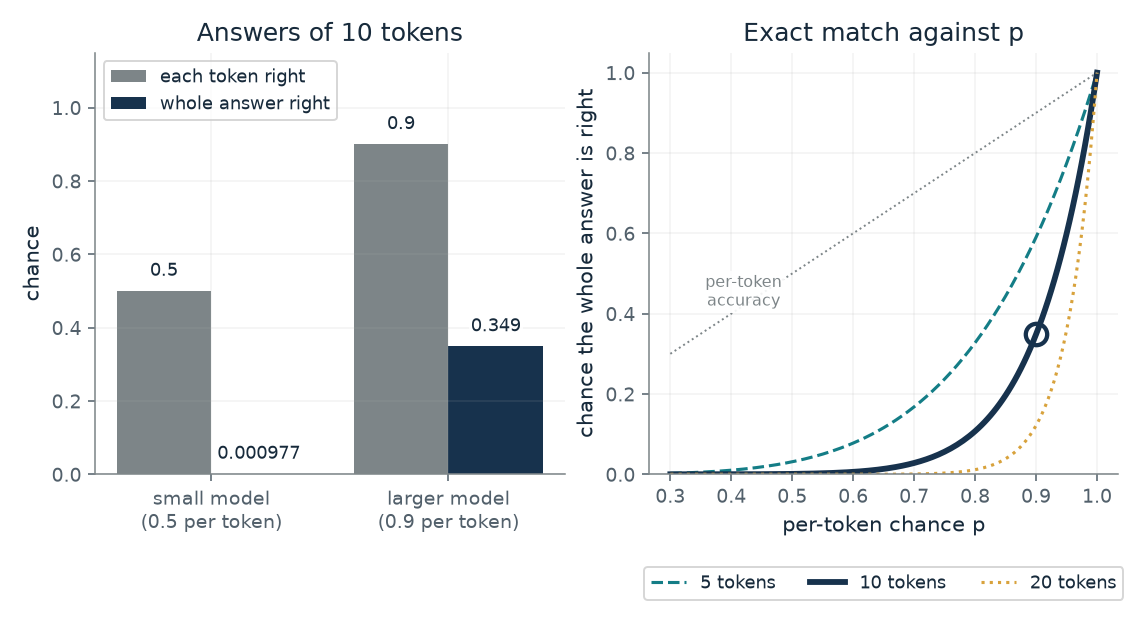

- **Per-token chance p:** 0.9
- **Whole answer right (p^L):** 0.349
- **Whole answer over per-token chance, p^(L-1):** 0.387
- **p needed for an even chance:** 0.933

With each of 10 tokens right with chance 0.9, the whole answer is right with chance 0.349. To get an even chance of a whole answer at length 10, each token must be right 0.933 of the time.

0.9^10 = 0.349. Even chance: 0.5^(1/10) = 0.933.

In [2]:
figure, values, explanation = exact_picture(**{'p': 0.9, 'length': 10})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Why does a whole answer jump when each piece improves steadily?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Per-token chance p = 0.9, Tokens in the answer (L) = 10: A small model at 0.5 per token gets a whole answer right 0.001 of the time, and 0.9 gives 0.349. Per-token accuracy rose by a factor of 1.8 while exact match rose by about 357 times: a steady improvement looks like a leap.

**Takeaway:** Under all-or-nothing scoring, the chance of a whole answer is a power of the per-token chance, so a steady rise looks like a sudden jump. A smoother score on the same outputs shows steady improvement.

**Why it matters:** A jump in a score can come from the scoring rule and not from a change inside the model. The chapter says a steep rise in a brain measure would likewise need a second observation before anyone calls it a threshold.

**In brains and behavior:** Workspace theory expects a fact to enter its shared space all at once, like a switch. The chapter says a sudden jump is easy to see and easy to misread, and no brain study here uses this formula.

**In machines:** Schaeffer and colleagues argue that many reported jumps in language-model ability come from the researcher's scoring rule, with GPT-3 family models on two-digit multiplication as an example. This is a specification of one simple model of scoring, not a measurement of any model.

**Where it applies:** A simplified fixed-length answer with no extra tokens and independent tokens, which the paper says is untrue of real text. The paper does not claim real jumps never happen.

**Check your understanding:** What per-token chance gives an even chance of a whole ten-token answer?

<details><summary>Show the answer</summary>

0.5 to the power one tenth, about 0.933: each token must be right about 93 times in 100.

</details>

*Source: Chapter 31, A sudden jump in a score can come from the scoring rule. Book formula for the model of Schaeffer and colleagues, with the chapter's round numbers: a small model right half the time per token and a larger one nine times in ten, on ten tokens, giving 0.001 and 0.349. The other values of p and L are the companion's variations. The chapter says the 0.5 and 0.9 numbers are its own arithmetic, not the paper's.*

## C31-D02: How much can a zero among 655 electrodes rule out?

None of 655 front electrodes matched the predicted burst. If each had the same small chance of a detected match, how likely is that?

If every electrode had the same chance r of showing a detected match, the chance that none does is the chance of one miss multiplied by itself n times. That falls quickly as r or n grows. The rate at which it crosses 5 in 100 depends on n, and n is not known, because neighboring electrodes are related. With fewer independent electrodes the zero rules out less.

$$
P(\text{all miss})=(1-r)^{n},\qquad r_{\text{cutoff}}=1-0.05^{1/n}
$$

**Symbols:** r: the chance one electrode gives a detected match to the predicted pattern; n: the number of electrodes counted as independent; r_cutoff: the rate above which an all-miss has chance below 5 in 100

**Predict before looking:** If each of 655 electrodes had a one in a thousand chance of a detected match, predict the chance that all would miss.

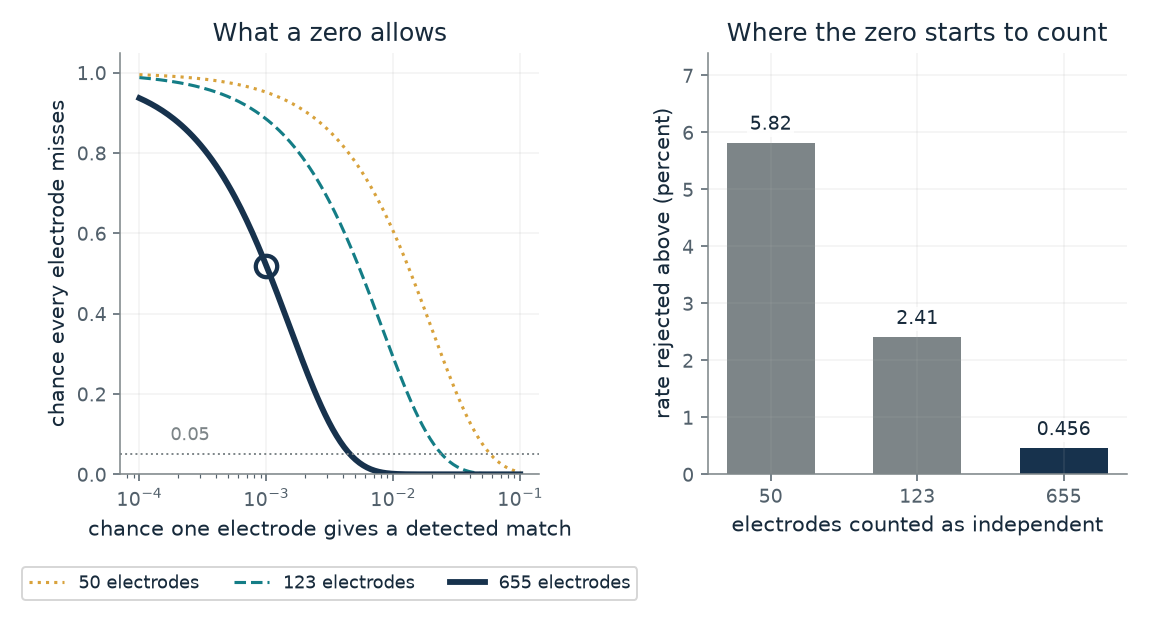

- **Chance every electrode misses:** 0.519
- **Detected matches expected:** 0.655
- **This rate rejected by a zero:** no
- **Rate rejected above (percent):** 0.456

If each of 655 independent electrodes had a detected-match chance of 0.001, all of them would miss with chance 0.519. A zero rejects rates above about 0.456 percent under this model, and it is evidence against high detected-match rates, not proof.

P(all miss) = (1 - 0.001)^655 = 0.519. Cutoff: 1 - 0.05^(1/655) = 0.00456.

In [3]:
figure, values, explanation = zero_picture(**{'rate': 0.001, 'electrodes': 655})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How much can a zero among 655 electrodes rule out?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Chance one electrode gives a detected match = 0.001, Electrodes counted as independent = 655: All 655 miss with chance 0.519, about even, so a zero would be unsurprising at one in a thousand. Switch to a rate of 0.005 and the chance falls below 5 in 100, so the zero counts against rates higher than about half a percent, under independence.

**Takeaway:** A zero is evidence against high detected-match rates under a model, not proof the pattern is absent. The fewer electrodes count as independent, the less it rules out.

**Why it matters:** Finding nothing proves little unless the method could have found something. The paper's positive control in the back of the brain shows the method can detect the pattern somewhere, and does not say how common it should be in the front.

**In brains and behavior:** Of 655 front electrodes only 123 responded to the pictures at all, and none matched the onset and offset pattern in the preregistered analysis. The chapter notes one electrode fit in another signal and one in an exploratory analysis. The paper named no winner.

**In machines:** Not applicable: this is a counting argument about a recording, not a software system.

**Where it applies:** Independent electrodes, which is probably false because neighboring contacts move together, so a zero rules out less. The calculation concerns detected matches, not the pattern's true prevalence, and limited coverage or sensitivity could hide real responses.

**Check your understanding:** For 123 electrodes, which rate gives all-miss chance 0.05?

<details><summary>Show the answer</summary>

1 - 0.05^(1/123) = 0.024, about 2.4 percent.

</details>

*Source: Chapter 31, How much a zero can rule out. The chapter's own rough check (not the paper's): at one electrode in a thousand the all-miss chance is 0.52, a cutoff of about 0.5 percent for 655, 2.4 for 123 and 6 for 50 electrodes. The 655 and 123 electrode counts are the study's as the chapter gives them; the other rates are the companion's variations.*

## C31-D03: What does a Bayes factor of 5 to 9 do to the odds?

The electrodes' Bayes factors, 5.11 to 8.65, favored no orientation signal in the front. How much do they move a belief?

Before the data the reader holds some odds for 'no orientation signal'. The Bayes factor says how much the data favor that explanation over the other. Multiplying gives the new odds, and odds convert to a probability of that model against the one alternative, not of the claim about the whole front. The same factor gives a lower probability to a reader who began doubtful and a higher one to a reader who began convinced.

$$
\text{posterior odds}=\text{Bayes factor}\times\text{prior odds},\qquad p=\frac{\text{odds}}{1+\text{odds}}
$$

**Symbols:** Bayes factor: how much better one explanation fits the data than the other; 1 is a tie; prior odds: the odds for 'no orientation signal' before the data, a choice; p: the probability for 'no orientation signal' after the data

**Predict before looking:** With even prior odds, predict the probability of no orientation signal after a Bayes factor of 5.11 and of 8.65.

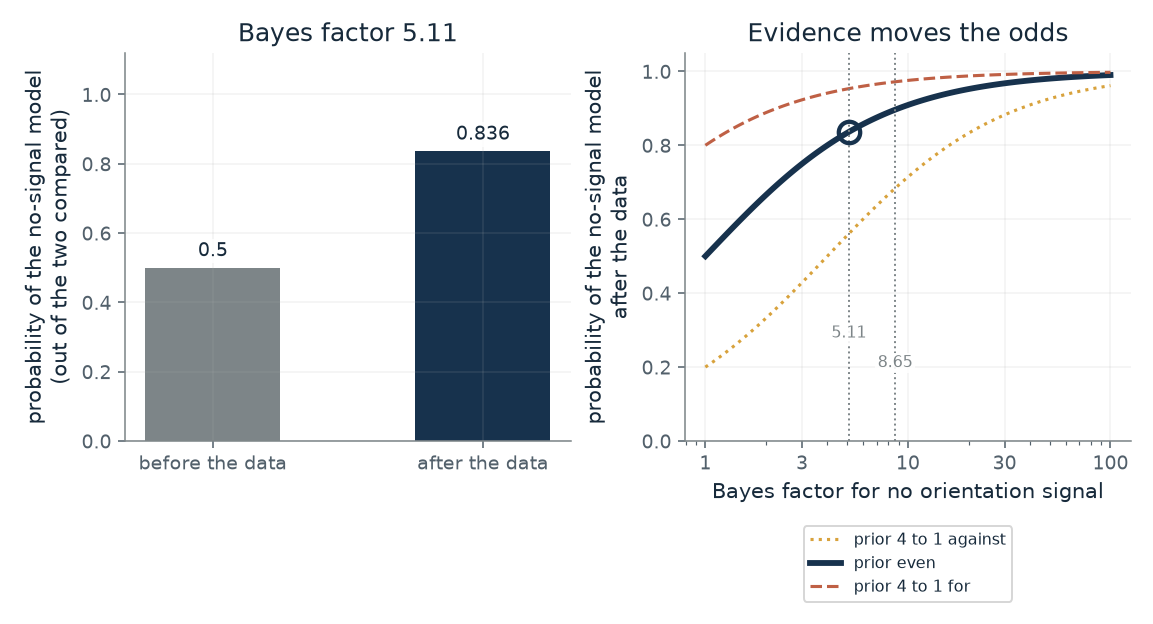

- **Prior odds, no-signal model:** 1
- **Posterior odds:** 5.11
- **Probability of that model, before:** 0.5
- **Probability of that model, after:** 0.836

A Bayes factor of 5.11 for the no-signal model turns prior odds of 1 into odds of 5.11, so that model's probability, out of the two compared, goes from 0.5 to 0.836. This is arithmetic on a prior chosen here, not a fact about the brain, and it is not in the paper.

Posterior odds = Bayes factor x prior odds = 5.11 x 1 = 5.11. Probability = odds/(1 + odds) = 0.836.

In [4]:
figure, values, explanation = bayes_picture(**{'bayes_factor': 5.11, 'prior_odds': 1})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='What does a Bayes factor of 5 to 9 do to the odds?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Bayes factor for no orientation signal = 5.11, Prior odds for no signal = 1: With even odds, a factor of 5.11 gives a probability of 0.836 for the no-signal explanation against the one alternative, given even prior odds, and 8.65 gives 0.896. Neither is certainty, and a prior of 4 to 1 against moves them to about 0.56 and 0.68. This is arithmetic on a stated prior, not a fact about the brain. The factor measures the data's push; the prior is a separate choice.

**Takeaway:** A Bayes factor multiplies the odds. A factor of 5 to 9 is called moderate evidence on a common convention (not the paper's wording) and does not settle the question by itself.

**Why it matters:** The chapter says a factor of 1 is a tie and larger numbers mean stronger support. How strong depends on where one started, and on whether the method could have found a signal.

**In brains and behavior:** The reported factors concern orientation in front-brain electrodes. MEG read orientation weakly (35 percent against 33 by chance), which the paper says may have leaked in from the back of the brain.

**In machines:** The decoder is standard machine learning used as a tool on brain data, not as a model of the mind.

**Where it applies:** The Bayes factor is taken at face value for two explanations, 'no orientation signal' and 'an orientation signal', and a prior odds are chosen by the reader. The result is the probability of the no-signal model against that one alternative, not the probability that the front carries no orientation information. The reported 5.11 to 8.65 is a range over several analyses, each to be read one at a time; the page takes one value at a time. The chapter says the paper graded the orientation result inconclusive: the evidence leans against the theory but limits of the method could explain it.

**Check your understanding:** With prior odds 1 to 4 against no signal (0.25) and a Bayes factor of 8.65, what are the posterior odds and probability?

<details><summary>Show the answer</summary>

8.65 x 0.25 = 2.16 in odds, which is 2.16/3.16 = 0.684.

</details>

*Source: Chapter 31, Category was readable in the front, but orientation mostly was not. The chapter's reported Bayes factors for the electrodes (5.11 to 8.65, favoring no orientation signal) and its definition that 1 is a tie. The conversion to a probability with chosen prior odds is the companion's own arithmetic on a stated prior and is not in the paper; it is not a fact about the brain. The paper's factors depend on its own model of the effect.*

## C31-D04: Did a shared workspace help, and what did the slot count do?

In one software design, how did the number of workspace slots change a ball-separation score?

Modules compete to write into a small number of slots, and whatever wins is read by all modules. Among the slot counts tried, the score was highest at five. On the chapter's reading (not the paper's) too few slots starve the modules; the paper reads the fall after eight slots as the cost of a looser limit. The adjusted Rand index compares the model's grouping of the balls to the true grouping.

$$
\text{difference}=\text{score}_{\text{slots}}-\text{score}_{\text{comparison}},\qquad \text{ratio}=\frac{\text{score}_{\text{slots}}}{\text{score}_{\text{comparison}}}
$$

**Symbols:** score: the adjusted Rand index: 1 is a perfect grouping of the balls, near 0 is chance; slots: memory slots in the shared workspace: each a list of numbers that modules compete to write to; no workspace: the same design with modules passing messages in pairs, not zero slots

**Predict before looking:** Compared with no workspace, predict whether two slots help or hurt, and whether ten slots do better than five.

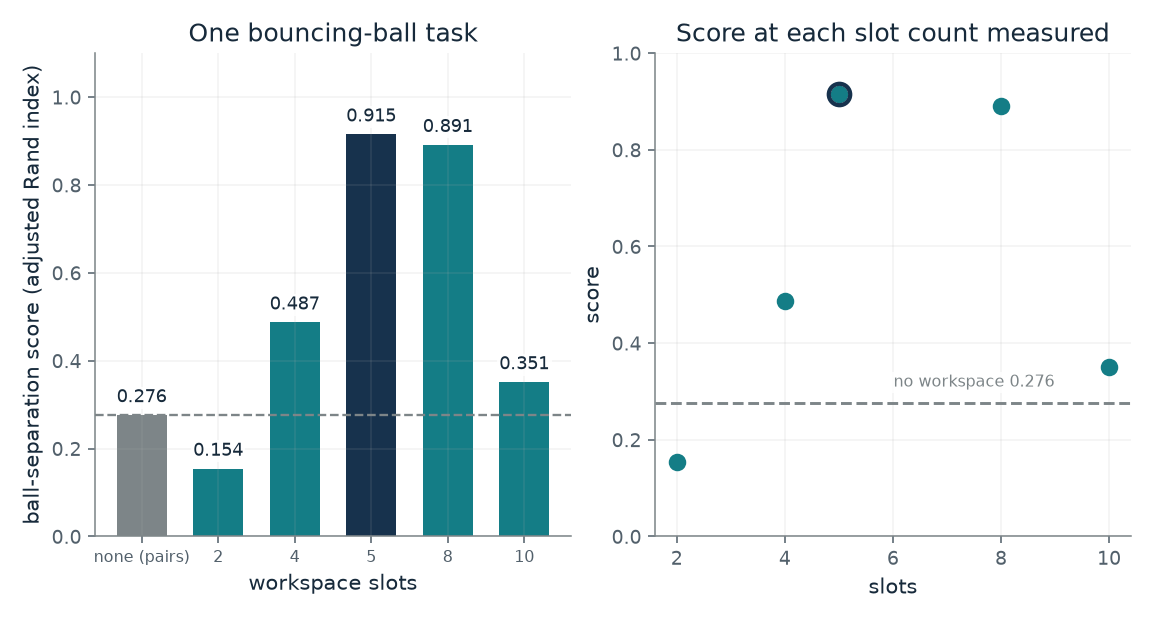

- **Score:** 0.915
- **Difference from no workspace:** 0.639
- **Ratio to no workspace:** 3.32
- **Above no workspace:** yes

With 5 slots the score is 0.915, 0.639 above the score with no workspace (0.276), a ratio of 3.32. One task and one design; the chapter says two slots scored below no workspace.

Difference = 0.915 - 0.276 = 0.639. Ratio = 0.915/0.276 = 3.32.

In [5]:
figure, values, explanation = slot_picture(**{'slots': 5, 'versus': 'no workspace'})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Did a shared workspace help, and what did the slot count do?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Workspace slots = 5, Compare with = no workspace: Five slots score 0.915 against 0.276 with no workspace, a ratio of 3.32. Choose 2 slots and the score is 0.154, below no workspace. Choose 10 and it falls back to 0.351. In this design the number of slots decided whether the shared space helped.

**Takeaway:** A shared space helped on this task, and its capacity decided whether: five slots far above no workspace, two below it, ten far below five.

**Why it matters:** The brain theory assumes a similar capacity limit on how many items the shared channel holds at once. The software paper notes in passing that human working memory holds fewer than ten items; no study here measures a slot count in a brain.

**In brains and behavior:** Workspace theory says the brain has a shared space built to get a fact to every part that needs it. No brain study here counts slots.

**In machines:** A reported result on one design and one task: the workspace is the team's own design, built on SCOFF, so the fair comparison is SCOFF with a workspace against SCOFF without one.

**Where it applies:** One design and one task. The paper reads the fall after eight slots as the cost of a looser limit, and the chapter's reading that too few slots starve the modules is the chapter's, not the paper's. No spread over runs is given in the chapter, so none is shown, and the right-hand panel shows only the five slot counts measured.

**Check your understanding:** How much higher is the five-slot score than the no-workspace score, in points and as a ratio?

<details><summary>Show the answer</summary>

0.915 - 0.276 = 0.639 points, and 0.915/0.276 = 3.32 times.

</details>

*Source: Chapter 31, Five shared slots helped a software workspace, and two hurt it. Reported results from the chapter and its source note on Goyal and colleagues' bouncing-ball task (the paper's table of this task): 0.276 with no workspace, and 0.154, 0.487, 0.915, 0.891, 0.351 with 2, 4, 5, 8, 10 slots. The differences and ratios are the companion's arithmetic.*

## C31-D05: What happens to the leap if tokens are not independent?

The formula p to the power L treats tokens as independent. What if tokens sometimes go together, all right or all wrong?

Independent tokens multiply, so a long answer needs every token right and the chance falls with length. Tokens that go together share one outcome, so the whole answer is right with chance p regardless of length. Real tokens are somewhere in between, so a positive relation among tokens would make the rise in exact match less abrupt than p^L predicts; this mixture does not say by how much.

$$
P(\text{exact})=t\,p+(1-t)\,p^{L}
$$

**Symbols:** t: the share of the time the tokens succeed or fail as one unit; p: the per-token chance of being right; L: the number of tokens

**Predict before looking:** If the tokens always go together (t = 1), predict the exact-match chance of the small and larger model.

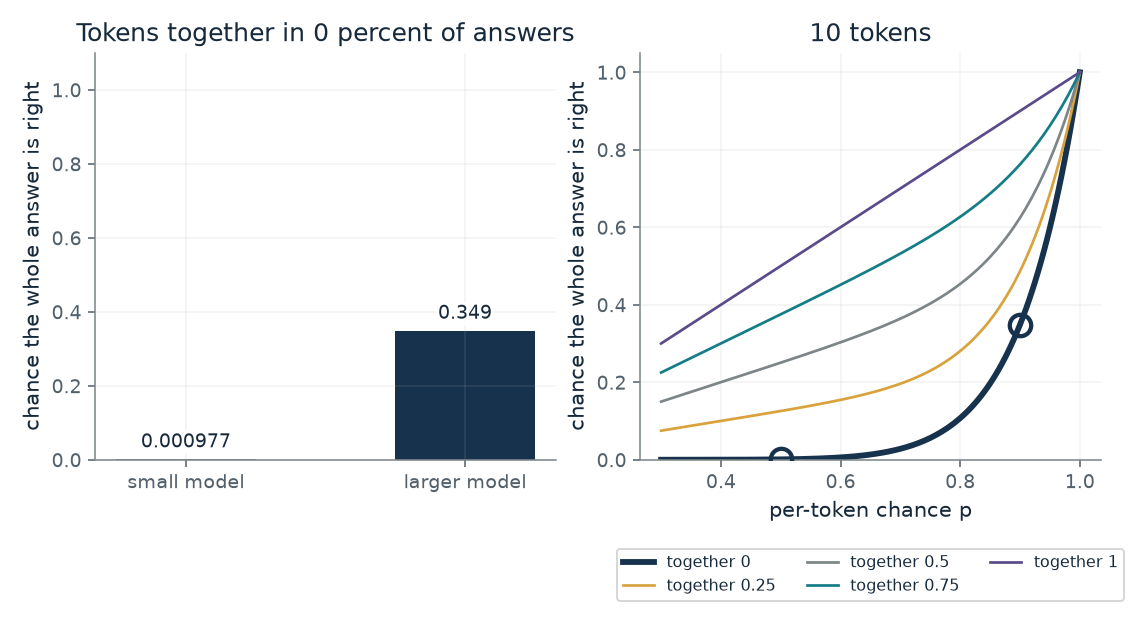

- **Small model, whole answer:** 0.000977
- **Larger model, whole answer:** 0.349
- **Gap:** 0.348
- **Ratio, larger over small:** 357

If tokens go together in 0 percent of answers and are independent in the rest, a whole 10-token answer is right 0.000977 of the time for the small model and 0.349 for the larger one. The p^L formula is the case where tokens never go together, which the paper says is untrue of real text.

P = t x p + (1 - t) x p^10. Small: 0 x 0.5 + 1 x 0.000977 = 0.000977. Larger: 0 x 0.9 + 1 x 0.349 = 0.349.

In [6]:
figure, values, explanation = correlated_picture(**{'together': 0, 'length': 10})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='What happens to the leap if tokens are not independent?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Share of the time tokens go together (t) = 1, Tokens in the answer (L) = 10: When tokens always go together the whole answer is right with chance p, so exact match is 0.5 and 0.9: no leap, just the per-token accuracy. At t = 0 it is the chapter's 0.001 and 0.349.

**Takeaway:** The sudden look of the jump depends on the independence assumption. The more tokens go together, the closer exact match is to per-token accuracy: the ratio between the two models falls from about 357 to 1.8 and the curve straightens, although the absolute gap does not shrink (0.348 at t = 0, 0.400 at t = 1).

**Why it matters:** A formula with a stated, admittedly untrue assumption explains a pattern without proving how large it is in real text. The result is a reason to check the scoring rule, not a prediction.

**In brains and behavior:** None.

**In machines:** A specification: the arithmetic of a mixture of two simple cases. Schaeffer and colleagues also scored the same outputs by how close each answer came and found smooth improvement.

**Where it applies:** A mixture: with chance t all tokens share one outcome (right with chance p), otherwise they are independent. Real text has no such clean split. The small and larger models are the chapter's 0.5 and 0.9 per-token cases.

**Check your understanding:** At t = 0.5 and L = 10, what is the exact-match chance for the larger model (p = 0.9)?

<details><summary>Show the answer</summary>

0.5 x 0.9 + 0.5 x 0.349 = 0.45 + 0.174 = 0.624.

</details>

*Source: Chapter 31, A sudden jump in a score can come from the scoring rule. The companion's own illustration. The chapter says the formula treats tokens as independent, which the paper says is untrue of real text; the mixture here is not from the chapter or the paper and is one simple way to relax independence.*

## Bring it to your own question

Before reading a zero or a sudden jump, ask what the method could have found and whether a smoother score tells the same story.

Use the `mmi-ch31-making-information-available` skill to choose a relevant equation, work with your inputs, and interpret the result. The skill should explain the assumptions and distinguish an illustration from evidence about your particular situation.